# **Preparing Dependancies**

In [1]:
!pip freeze > requirements.txt

In [1]:
!pip install -q diffusers transformers accelerate
!pip install -q torch torchvision
!pip install -q Pillow matplotlib numpy

# **Kriteria 1: Melakukan Image Generation dari Teks (Text-to-Image)**

## **Load Base Pipeline Model**

In [5]:
import torch
from diffusers import (
    StableDiffusionPipeline,
    StableDiffusionInpaintPipeline,
    StableDiffusionImg2ImgPipeline,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler,
    DDIMScheduler,
)
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

MODEL_ID = "runwayml/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    safety_checker=None,
).to(device)
pipe.enable_attention_slicing()

print("Base pipeline loaded successfully!")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its resul

Base pipeline loaded successfully!


## **Generate Image**

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

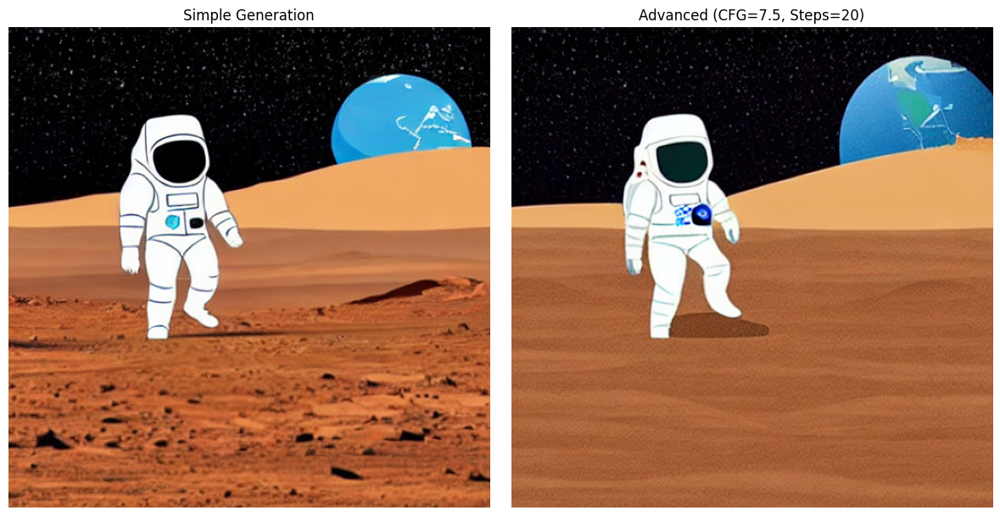

In [6]:
negative_prompt = (
    "photorealistic, realistic, photograph, 3d render, messy, blurry, "
    "low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
)
prompt = (
    "An astronaut stands on the surface of Mars, the astronaut is in a cartoon illustration style, his spacesuit is white with a helmet, the image of the earth is in the upper right corner of the starry and dark sky, the dusty ground is grayish brown, the art style is flat towards semi-realistic."
)

def generate_simple_image(pipe, prompt, negative_prompt, seed):
    generator = torch.Generator(device=device).manual_seed(seed)
    image = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
    ).images[0]
    return image

def generate_advanced_image(pipe, prompt, negative_prompt, seed,
                             guidance_scale, num_inference_steps):
    generator = torch.Generator(device=device).manual_seed(seed)
    image = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps,
    ).images[0]
    return image

simple_image   = generate_simple_image(pipe, prompt, negative_prompt, seed=222)
advanced_image = generate_advanced_image(
    pipe, prompt, negative_prompt,
    seed=222, guidance_scale=7.5, num_inference_steps=20
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(simple_image);   axes[0].set_title("Simple Generation");           axes[0].axis("off")
axes[1].imshow(advanced_image); axes[1].set_title("Advanced (CFG=7.5, Steps=20)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## **Generate Image with Hyperparameter Configuration**

  0%|          | 0/20 [00:00<?, ?it/s]

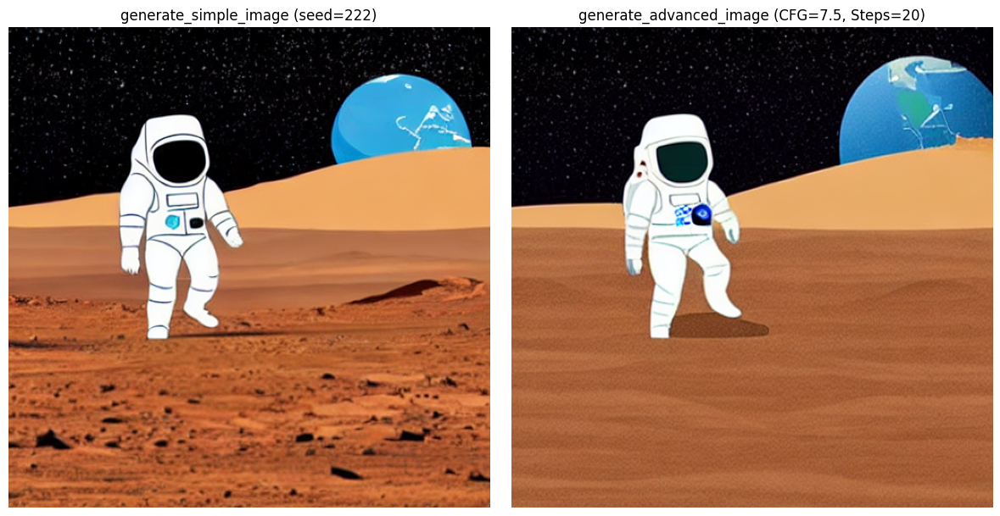

In [7]:
advanced_image_v2 = generate_advanced_image(
    pipe, prompt, negative_prompt,
    seed=222, guidance_scale=7.5, num_inference_steps=20
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(simple_image);      axes[0].set_title("generate_simple_image (seed=222)");          axes[0].axis("off")
axes[1].imshow(advanced_image_v2); axes[1].set_title("generate_advanced_image (CFG=7.5, Steps=20)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## **Guidance Scale Comparison**

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

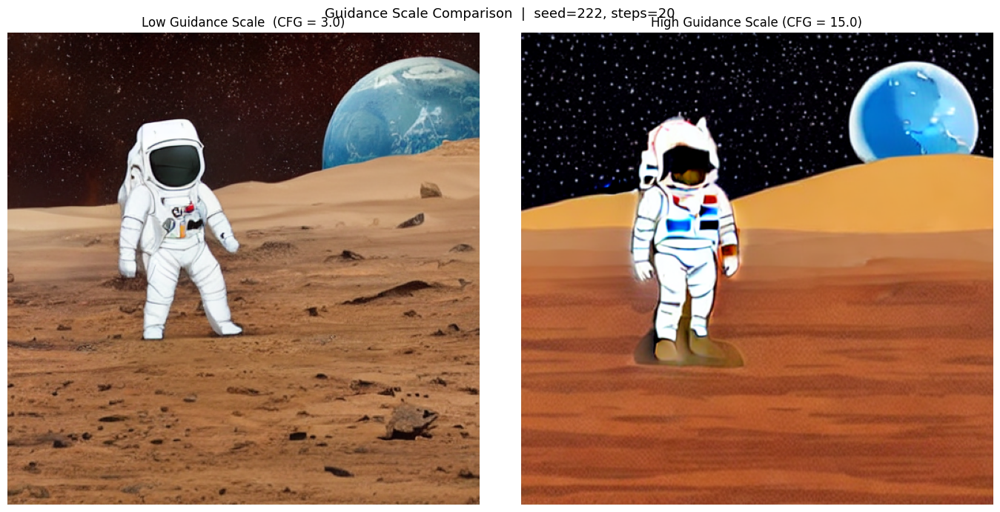

In [8]:
low_cfg_image  = generate_advanced_image(pipe, prompt, negative_prompt,
                                          seed=222, guidance_scale=3.0,  num_inference_steps=20)
high_cfg_image = generate_advanced_image(pipe, prompt, negative_prompt,
                                          seed=222, guidance_scale=15.0, num_inference_steps=20)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(low_cfg_image);  axes[0].set_title("Low Guidance Scale  (CFG = 3.0)");  axes[0].axis("off")
axes[1].imshow(high_cfg_image); axes[1].set_title("High Guidance Scale (CFG = 15.0)"); axes[1].axis("off")
plt.suptitle("Guidance Scale Comparison  |  seed=222, steps=20", fontsize=13)
plt.tight_layout(); plt.show()

### **Guidance Scale Explanation:**
*   **Gambar dengan "Scale" Rendah (guidance\\_scale = 3.0):**   
*"Dengan skala bimbingan rendah, model memiliki kebebasan kreatif yang lebih besar sehingga gambar terlihat lebih *dreamlike* dan *painterly*."*
*"Detail objek kurang tajam, warna tampak lebih lembut, dan komposisi kadang menyimpang dari deskripsi prompt karena model tidak \"dipaksa\" mengikuti teks secara ketat."*
*"Variasi visual lebih kaya namun konsistensi dengan prompt lebih rendah."*

*   **Gambar dengan "Scale" Tinggi (guidance\\_scale = 15.0):**   
*"Pada skala bimbingan tinggi, setiap elemen dalam prompt direpresentasikan secara eksplisit dengan detail yang lebih tajam dan komposisi yang lebih dekat dengan deskripsi teks."*
*"Namun, nilai yang terlalu tinggi dapat memunculkan *over-saturation*, kontras berlebih, atau artefak pada tepi objek karena model terlalu agresif dalam mengikuti prompt di setiap langkah denoising."*


## **Inference Steps Comparison**

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

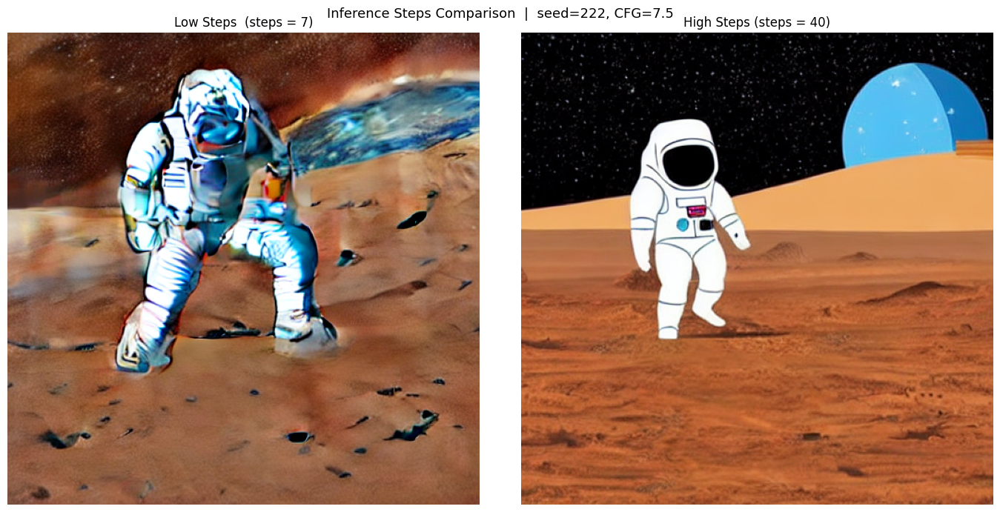

In [9]:
low_steps_image  = generate_advanced_image(pipe, prompt, negative_prompt,
                                            seed=222, guidance_scale=7.5, num_inference_steps=7)
high_steps_image = generate_advanced_image(pipe, prompt, negative_prompt,
                                            seed=222, guidance_scale=7.5, num_inference_steps=40)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(low_steps_image);  axes[0].set_title("Low Steps  (steps = 7)");  axes[0].axis("off")
axes[1].imshow(high_steps_image); axes[1].set_title("High Steps (steps = 40)"); axes[1].axis("off")
plt.suptitle("Inference Steps Comparison  |  seed=222, CFG=7.5", fontsize=13)
plt.tight_layout(); plt.show()

### **Inference Step Explanation:**

*   **Gambar dengan "Step" Rendah:**  
*"Dengan hanya 7 langkah denoising, gambar terlihat belum selesai — bentuk objek tampak kabur, tekstur kurang terdefinisi, dan noise atau artefak denoising masih terlihat di seluruh komposisi."
"Elemen halus seperti bintang, permukaan metalik, dan detail struktural astronaut belum sepenuhnya terbentuk, menghasilkan tampilan kasar dan tidak stabil secara visual."*
*   **Gambar dengan "Step" Tinggi:**  
*"Dengan 40 langkah denoising, gambar menunjukkan peningkatan signifikan pada ketajaman dan koherensi visual — tekstur lebih halus, tepi objek lebih bersih, dan komposisi keseluruhan terasa lebih stabil."
"Langkah tambahan memungkinkan detail halus untuk muncul dan disempurnakan, menghasilkan output berkualitas tinggi yang konsisten dengan deskripsi prompt."*

## **Batch Inference from One Prompt**

  0%|          | 0/20 [00:00<?, ?it/s]

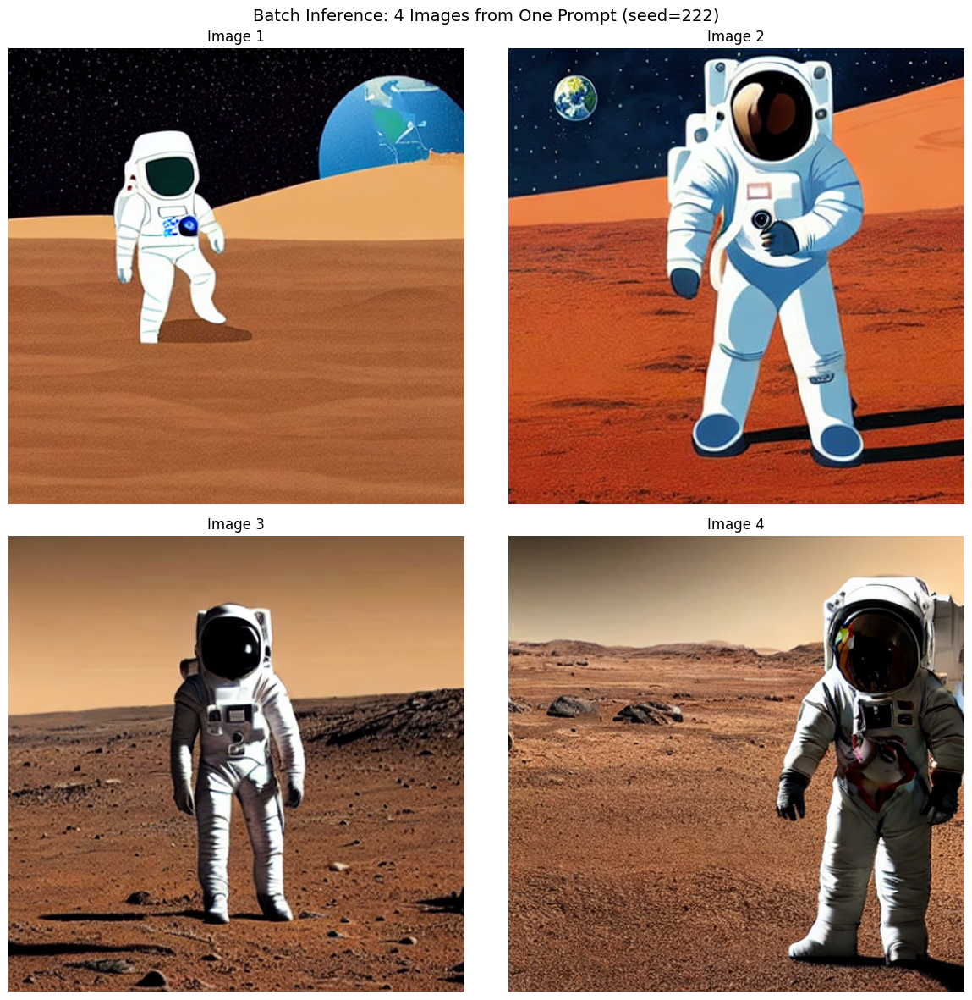

In [10]:
generator    = torch.Generator(device=device).manual_seed(222)
batch_result = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    generator=generator,
    guidance_scale=7.5,
    num_inference_steps=20,
    num_images_per_prompt=4,
)
batch_images = batch_result.images

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for idx, (ax, img) in enumerate(zip(axes.flatten(), batch_images)):
    ax.imshow(img); ax.set_title(f"Image {idx + 1}"); ax.axis("off")
plt.suptitle("Batch Inference: 4 Images from One Prompt (seed=222)", fontsize=14)
plt.tight_layout(); plt.show()

## **Load Scheduler**

  0%|          | 0/20 [00:00<?, ?it/s]

Generated with Euler A scheduler


  0%|          | 0/20 [00:00<?, ?it/s]

Generated with DPM++ scheduler


  0%|          | 0/20 [00:00<?, ?it/s]

Generated with DDIM scheduler


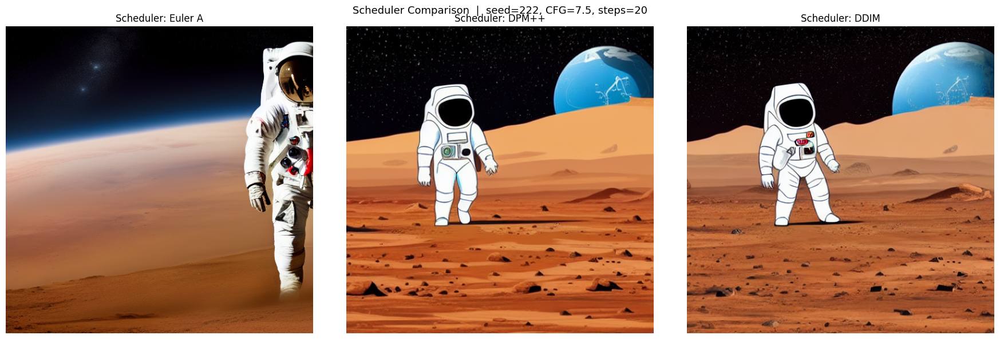

In [11]:
def load_scheduler(pipe, scheduler_name):
    if scheduler_name == "Euler A":
        pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
    elif scheduler_name == "DPM++":
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    elif scheduler_name == "DDIM":
        pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
    return pipe

scheduler_names  = ["Euler A", "DPM++", "DDIM"]
scheduler_images = {}

for name in scheduler_names:
    pipe = load_scheduler(pipe, name)
    gen  = torch.Generator(device=device).manual_seed(222)
    img  = pipe(
        prompt=prompt, negative_prompt=negative_prompt,
        generator=gen, guidance_scale=7.5, num_inference_steps=20,
    ).images[0]
    scheduler_images[name] = img
    print(f"Generated with {name} scheduler")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, img) in zip(axes, scheduler_images.items()):
    ax.imshow(img); ax.set_title(f"Scheduler: {name}"); ax.axis("off")
plt.suptitle("Scheduler Comparison  |  seed=222, CFG=7.5, steps=20", fontsize=13)
plt.tight_layout(); plt.show()

pipe = load_scheduler(pipe, "Euler A")   # reset to default

### **Scheduler Comparation:**

*   **Gambar dengan "Euler A Scheduler":**  
*"Euler Ancestral menghasilkan gambar dengan variasi visual yang kaya dan tekstur yang organik."
"Sifat stokastiknya memperkenalkan sedikit keacakan di setiap langkah sehingga menghasilkan gradasi warna yang lebih hidup dan ekspresif, cocok untuk output artistik yang dinamis."*
*   **Gambar dengan "DPM++ Scheduler":**  
*"DPM++ menghasilkan gambar yang lebih terstruktur dan tajam dengan kepatuhan prompt yang sangat baik dalam jumlah langkah yang lebih sedikit."
"Bersifat deterministik sehingga output dapat direproduksi dengan konsistensi visual yang tinggi dan kontras yang seimbang."*
*   **Gambar dengan "DDIM Scheduler":**  
*"DDIM menghasilkan gambar yang lebih konservatif dan dapat diprediksi dengan gradasi halus serta struktur yang koheren."
"Meskipun mungkin terlihat sedikit kurang detail dibanding dua scheduler lainnya pada jumlah langkah yang sama, DDIM menawarkan output paling konsisten dan mendukung interpolasi laten yang terkontrol."*

# **Kriteria 2: Menyempurnakan Gambar Melalui Image-to-Image**

## **Base + Refiner Image Generation**

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

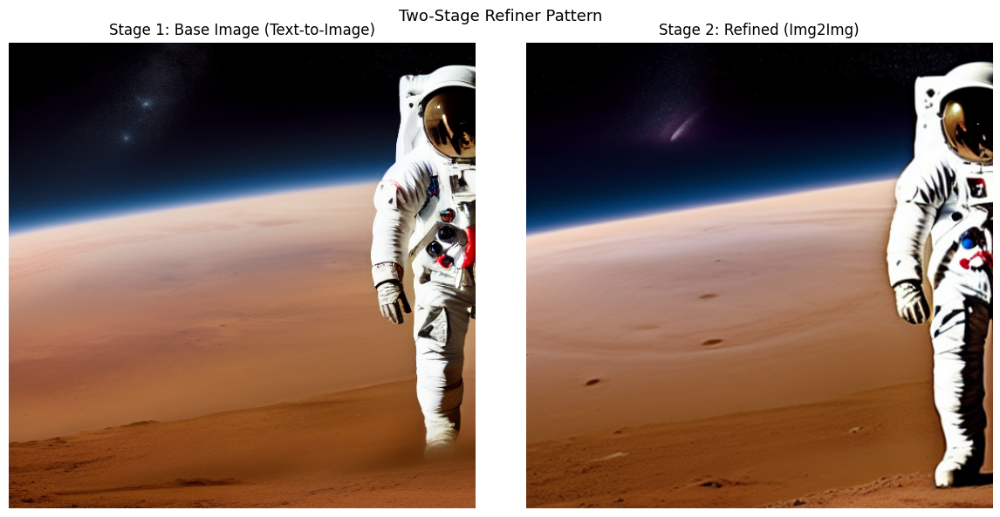

In [21]:
from diffusers import StableDiffusionImg2ImgPipeline

pipe_img2img = StableDiffusionImg2ImgPipeline(**pipe.components).to(device)

generator  = torch.Generator(device=device).manual_seed(222)
base_image = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    generator=generator,
    guidance_scale=7.5,
    num_inference_steps=20,
    output_type="latent",
    denoising_end=0.8,
).images

generator     = torch.Generator(device=device).manual_seed(222)
refined_image = pipe_img2img(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=base_image,
    generator=generator,
    guidance_scale=7.5,
    num_inference_steps=20,
    denoising_start=0.8,
).images[0]

with torch.no_grad():
    decoded = pipe.vae.decode(base_image / pipe.vae.config.scaling_factor).sample
    decoded = (decoded / 2 + 0.5).clamp(0, 1)
    base_pil = Image.fromarray(
        (decoded.cpu().permute(0, 2, 3, 1).float().numpy()[0] * 255).astype("uint8")
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(base_pil);      axes[0].set_title("Stage 1: Base Image (Text-to-Image)"); axes[0].axis("off")
axes[1].imshow(refined_image); axes[1].set_title("Stage 2: Refined (Img2Img)");          axes[1].axis("off")
plt.suptitle("Two-Stage Refiner Pattern", fontsize=13)
plt.tight_layout(); plt.show()

## **Inpainting**

### **Load Model Inpainting**

In [22]:
pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    safety_checker=None,
).to(device)
pipe_inpaint.enable_attention_slicing()
print("Inpainting pipeline loaded!")

def inpaint_engine(pipe, image, mask, prompt, seed=9, negative_prompt=None, guidance_scale=12.0, num_inference_steps=50):
    generator = torch.Generator(device=device).manual_seed(seed)

    if image.mode != "RGB":
        image = image.convert("RGB")
    if mask.mode != "L":
        mask = mask.convert("L")

    orig_size = image.size

    if image.size != (512, 512):
        image = image.resize((512, 512), resample=Image.LANCZOS)
        mask  = mask.resize((512, 512),  resample=Image.NEAREST)

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=image,
        mask_image=mask,
        generator=generator,
        guidance_scale=7.5,
        num_inference_steps=20,
    ).images[0]

    if orig_size != (512, 512):
        result = result.resize(orig_size, resample=Image.LANCZOS)

    return result

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diff

Inpainting pipeline loaded!


### **Manual Masking**

/tmp/ipykernel_11922/3606926203.py:6: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  manual_mask = Image.fromarray(mask_arr, mode="L")


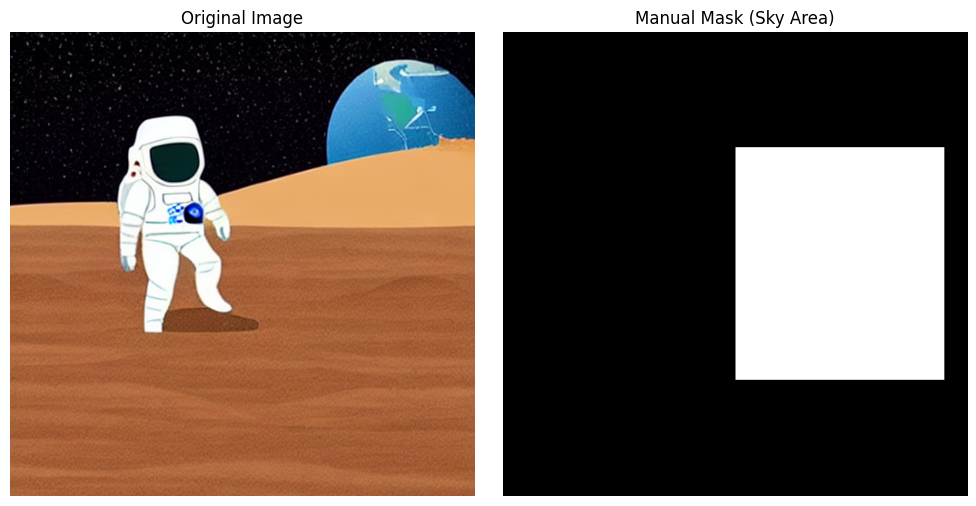

In [23]:
base_for_inpaint = advanced_image.resize((512, 512), resample=Image.LANCZOS)
w, h = base_for_inpaint.size

mask_arr = np.zeros((h, w), dtype=np.uint8)
mask_arr[int(h * 0.25):int(h * 0.75), int(w * 0.50):int(w * 0.95)] = 255
manual_mask = Image.fromarray(mask_arr, mode="L")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(base_for_inpaint); axes[0].set_title("Original Image");               axes[0].axis("off")
axes[1].imshow(manual_mask, cmap="gray"); axes[1].set_title("Manual Mask (Sky Area)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

### **Generate**

  0%|          | 0/20 [00:00<?, ?it/s]

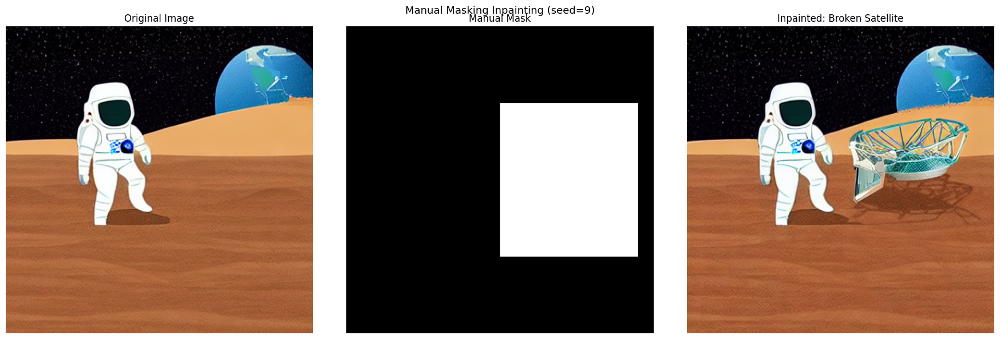

In [25]:
prompt_satellite = (
    "a small damaged broken satellite floating in space, "
    "broken solar panels, metallic debris, exposed mechanical parts, "
    "multi-legged structure, small scale object, "
    "highly detailed mechanical structure, sharp focus, "
    "semi-realistic illustration, cinematic lighting"
)

negative_prompt_satellite = (
    "blurry, low quality, distorted, messy, cartoon, drawing, painting, "
    "astronaut, human, person, planet, Earth, large object, "
    "photorealistic, photograph"
)

inpainted_result = inpaint_engine(
    pipe_inpaint, base_for_inpaint, manual_mask, prompt_satellite,
    seed=9, negative_prompt=negative_prompt_satellite,
    guidance_scale=12.0, num_inference_steps=50
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(base_for_inpaint);          axes[0].set_title("Original Image");              axes[0].axis("off")
axes[1].imshow(manual_mask, cmap="gray");  axes[1].set_title("Manual Mask");                 axes[1].axis("off")
axes[2].imshow(inpainted_result);          axes[2].set_title("Inpainted: Broken Satellite"); axes[2].axis("off")
plt.suptitle("Manual Masking Inpainting (seed=9)", fontsize=13)
plt.tight_layout(); plt.show()

current_image = inpainted_result   # carry forward

## **Inpainting Menggunakan Automasking**

### **load Model Segmentation Untuk Masking**

In [26]:
from transformers import pipeline as hf_pipeline

seg_pipeline = hf_pipeline(
    "image-segmentation",
    model="facebook/maskformer-swin-base-ade",
    device=0 if torch.cuda.is_available() else -1,
)
print("Segmentation model loaded!")

Loading weights:   0%|          | 0/648 [00:00<?, ?it/s]

Segmentation model loaded!


### **Masking with Segmentation Model**

`label_ids_to_fuse` unset. No instance will be fused.
/tmp/ipykernel_11922/2936307846.py:24: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(mask_arr, mode="L")


'['sky', 'background']' not found — using upper-40% fallback.


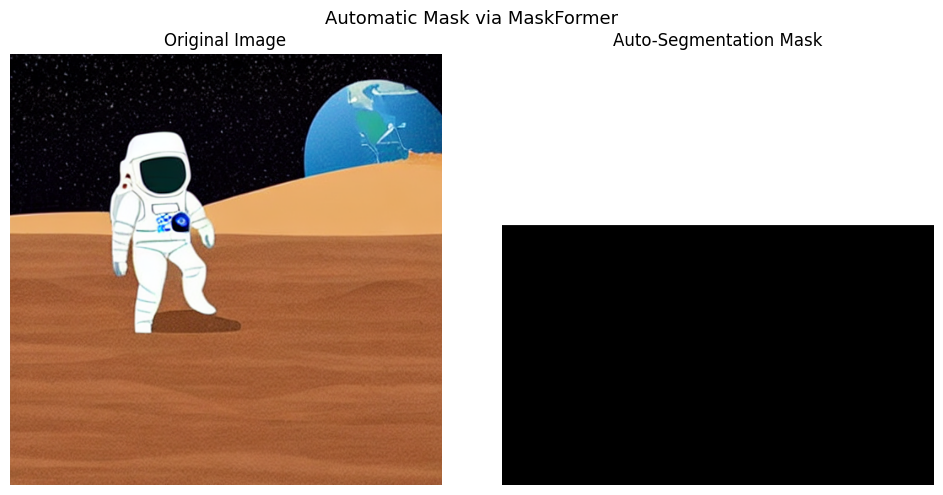

In [27]:
def create_segmentation_mask(image, target_labels=None):
    if target_labels is None:
        target_labels = ["sky", "ceiling", "background"]

    results   = seg_pipeline(image)
    mask_arr  = np.zeros((image.size[1], image.size[0]), dtype=np.uint8)
    found     = []

    for seg in results:
        label = seg["label"].lower()
        if any(t in label for t in target_labels):
            seg_mask = np.array(seg["mask"])
            if seg_mask.max() <= 1:
                seg_mask = (seg_mask * 255).astype(np.uint8)
            mask_arr = np.maximum(mask_arr, seg_mask.astype(np.uint8))
            found.append(label)

    if mask_arr.max() == 0:
        print(f"'{target_labels}' not found — using upper-40% fallback.")
        mask_arr[: int(mask_arr.shape[0] * 0.40), :] = 255
    else:
        print(f"Segments found: {found}")

    return Image.fromarray(mask_arr, mode="L")

auto_mask = create_segmentation_mask(base_for_inpaint, ["sky", "background"])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(base_for_inpaint);          axes[0].set_title("Original Image");           axes[0].axis("off")
axes[1].imshow(auto_mask, cmap="gray");    axes[1].set_title("Auto-Segmentation Mask");   axes[1].axis("off")
plt.suptitle("Automatic Mask via MaskFormer", fontsize=13)
plt.tight_layout(); plt.show()

### **Generate**

  0%|          | 0/20 [00:00<?, ?it/s]

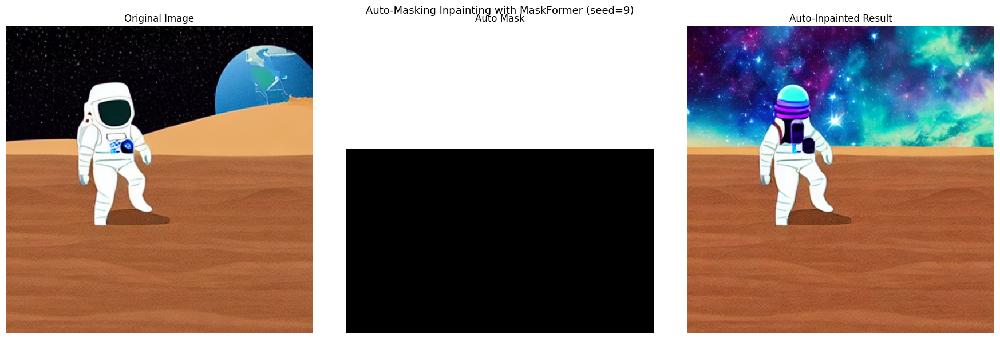

In [28]:
auto_prompt = (
    "a dense colorful nebula with purple and blue clouds, bright stars, "
    "cosmic dust, deep space"
)

auto_inpainted = inpaint_engine(
    pipe_inpaint, base_for_inpaint, auto_mask, auto_prompt, seed=9
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(base_for_inpaint);       axes[0].set_title("Original Image");        axes[0].axis("off")
axes[1].imshow(auto_mask, cmap="gray"); axes[1].set_title("Auto Mask");              axes[1].axis("off")
axes[2].imshow(auto_inpainted);         axes[2].set_title("Auto-Inpainted Result"); axes[2].axis("off")
plt.suptitle("Auto-Masking Inpainting with MaskFormer (seed=9)", fontsize=13)
plt.tight_layout(); plt.show()

## **Outpainting**

### **Prepare the Canvas**

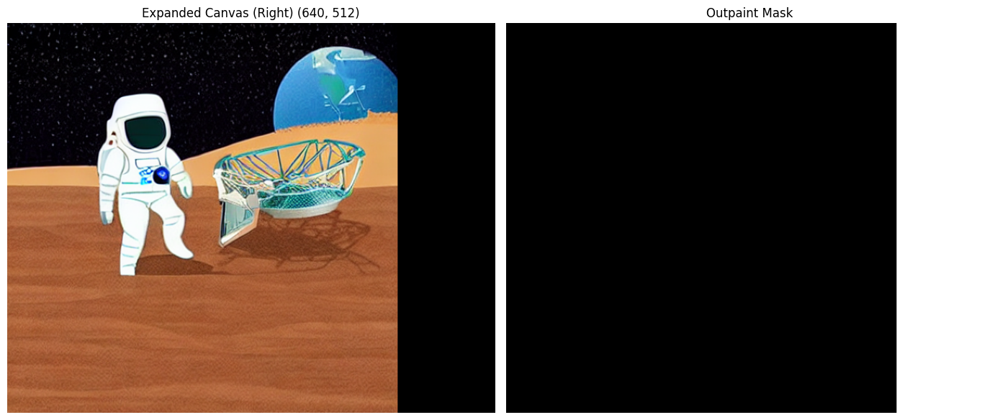

In [39]:
def prepare_outpainting(image, direction, expand_pixels=128):
    w, h = image.size

    if direction == "right":
        new_w, new_h = w + expand_pixels, h
        paste_x, paste_y = 0, 0
    elif direction == "left":
        new_w, new_h = w + expand_pixels, h
        paste_x, paste_y = expand_pixels, 0
    elif direction == "bottom":
        new_w, new_h = w, h + expand_pixels
        paste_x, paste_y = 0, 0
    elif direction == "top":
        new_w, new_h = w, h + expand_pixels
        paste_x, paste_y = 0, expand_pixels
    else:
        raise ValueError(f"Invalid direction: {direction!r}")

    new_w -= new_w % 8
    new_h -= new_h % 8

    canvas = Image.new("RGB", (new_w, new_h), color=(0, 0, 0))
    canvas.paste(image, (paste_x, paste_y))

    mask = Image.new("L", (new_w, new_h), 255)
    mask.paste(Image.new("L", image.size, 0), (paste_x, paste_y))

    return canvas, mask

canvas_r, mask_r = prepare_outpainting(inpainted_result, direction="right", expand_pixels=128)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(canvas_r);           axes[0].set_title(f"Expanded Canvas (Right) {canvas_r.size}"); axes[0].axis("off")
axes[1].imshow(mask_r, cmap="gray"); axes[1].set_title("Outpaint Mask");                            axes[1].axis("off")
plt.tight_layout(); plt.show()

### **Generate**

  0%|          | 0/20 [00:00<?, ?it/s]

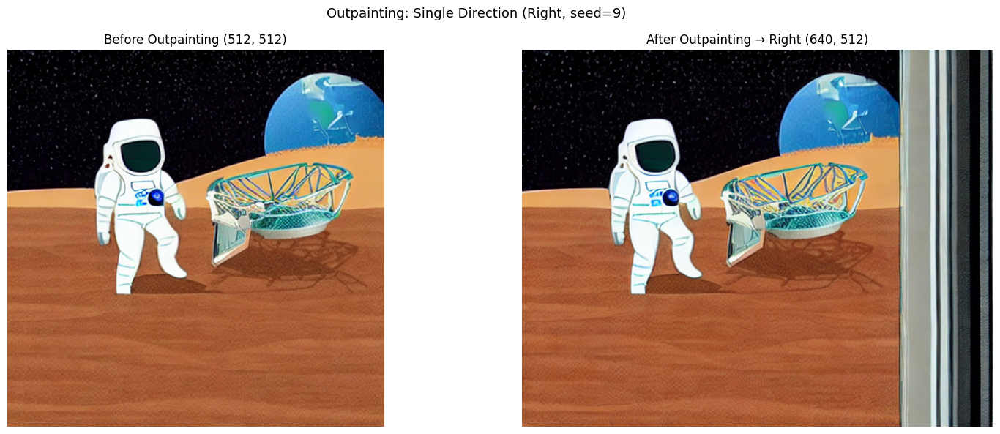

In [47]:
outpaint_prompt = (
    "spacecraft window frame viewed from inside space station, "
    "thick dark metallic frame with bolts, multiple connected window panels, "
    "deep black space and stars visible outside, blue Earth atmosphere glow, "
    "interior dark metal wall of ISS, cool blue ambient lighting, "
    "semi-realistic digital illustration, cinematic, sharp focus, high detail"
)

outpainted_image = inpaint_engine(
    pipe_inpaint, canvas_r, mask_r, outpaint_prompt, seed=9
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(inpainted_result);  axes[0].set_title(f"Before Outpainting {inpainted_result.size}"); axes[0].axis("off")
axes[1].imshow(outpainted_image); axes[1].set_title(f"After Outpainting → Right {outpainted_image.size}"); axes[1].axis("off")
plt.suptitle("Outpainting: Single Direction (Right, seed=9)", fontsize=13)
plt.tight_layout(); plt.show()

## **Outpainting Zoom Out**

### **Prepare Canvas for Zoom Out**

In [55]:
def zoom_out_iterative(image, pipe_inpaint, prompt, expand_pixels=128, seed=9):
    directions = ["left", "right", "top", "bottom"]
    results    = [image.copy()]
    current    = image.copy()

    for direction in directions:
        print(f"Expanding {direction}…  (current size: {current.size})")
        canvas, mask = prepare_outpainting(current, direction, expand_pixels)
        current      = inpaint_engine(pipe_inpaint, canvas, mask, prompt, seed)
        results.append(current.copy())
        print(f"  → new size: {current.size}")

    return results

zoom_prompt = (
    "spacecraft window frame viewed from inside space station, "
    "thick dark metallic frame with bolts, multiple connected window panels, "
    "deep black space and stars visible outside, blue Earth atmosphere glow, "
    "interior dark metal wall of ISS, cool blue ambient lighting, "
    "semi-realistic digital illustration, cinematic, sharp focus, high detail"
)

zoom_results = zoom_out_iterative(
    inpainted_result, pipe_inpaint, zoom_prompt, expand_pixels=128, seed=9
)
print(f"Generated {len(zoom_results)} images in zoom-out sequence.")

Expanding left…  (current size: (512, 512))


  0%|          | 0/20 [00:00<?, ?it/s]

  → new size: (640, 512)
Expanding right…  (current size: (640, 512))


  0%|          | 0/20 [00:00<?, ?it/s]

  → new size: (768, 512)
Expanding top…  (current size: (768, 512))


  0%|          | 0/20 [00:00<?, ?it/s]

  → new size: (768, 640)
Expanding bottom…  (current size: (768, 640))


  0%|          | 0/20 [00:00<?, ?it/s]

  → new size: (768, 768)
Generated 5 images in zoom-out sequence.


### **Generate**

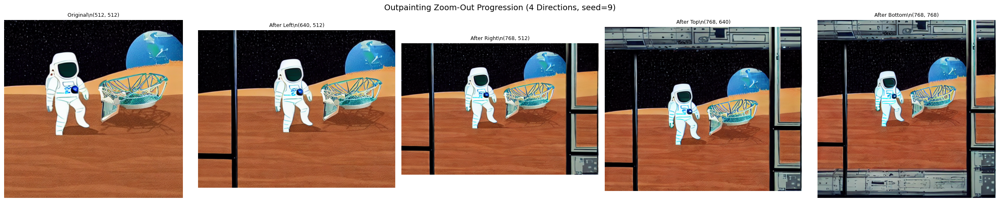

Original size : (512, 512)
Final size    : (768, 768)


In [56]:
labels = ["Original", "After Left", "After Right", "After Top", "After Bottom"]
n      = len(zoom_results)

fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
if n == 1:
    axes = [axes]

for ax, img, label in zip(axes, zoom_results, labels):
    ax.imshow(img)
    ax.set_title(f"{label}\\n{img.size}", fontsize=9)
    ax.axis("off")

plt.suptitle("Outpainting Zoom-Out Progression (4 Directions, seed=9)", fontsize=14)
plt.tight_layout(); plt.show()

print(f"Original size : {zoom_results[0].size}")
print(f"Final size    : {zoom_results[-1].size}")